In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv('course_lead_scoring_2026.csv')

In [3]:
data.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [18]:
data.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [8]:
data.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [10]:
categorical_columns = data.select_dtypes(include=['object', 'str', 'category']).columns.tolist()
categorical_columns

['lead_source', 'industry', 'employment_status', 'location']

In [11]:
numerical_columns = data.select_dtypes(include='number').columns.tolist()
numerical_columns

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score',
 'converted']

In [15]:
data[numerical_columns] = data[numerical_columns].fillna(0.0)

In [17]:
data[categorical_columns] = data[categorical_columns].fillna('NA')

In [22]:
from sklearn.model_selection import train_test_split

from sklearn.metrics import roc_curve

In [21]:
df_full_train, df_test = train_test_split(data, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [26]:
X_train = df_train.drop(labels = 'converted', axis=1)
X_val = df_val.drop(labels = 'converted', axis=1)
X_test = df_test.drop(labels = 'converted', axis=1)

y_train = np.array(df_train.converted.values)
y_val = np.array(df_val.converted.values)
y_test = np.array(df_test.converted.values)

In [29]:
from sklearn.feature_extraction import DictVectorizer

In [31]:
from sklearn.linear_model import LogisticRegression

In [50]:
from sklearn.metrics import auc

In [53]:
numerical_columns_for_auc = numerical_columns.remove('converted')
for num in numerical_columns:
    fpr, tpr, thresholds = roc_curve(y_train,X_train[num])
    aucs = auc(fpr, tpr)
    print(f'{num} auc = {aucs}\n')

annual_income auc = 0.6081977776250831

number_of_courses_viewed auc = 0.7229894623989618

interaction_count auc = 0.7649203047563227

lead_score auc = 0.7882254810906102



In [30]:
dv = DictVectorizer(sparse=False)
train_dict = X_train.to_dict(orient='records')
X_train_d = dv.fit_transform(train_dict)

val_dict = X_val.to_dict(orient='records')
X_val_d = dv.transform(val_dict)
X_train_d

array([[8.0198e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        5.0000e+00],
       [5.0548e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        2.0000e+00],
       [7.6300e+04, 0.0000e+00, 1.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00],
       ...,
       [2.1561e+04, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00],
       [3.1691e+04, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        3.0000e+00],
       [4.6342e+04, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        5.0000e+00]], shape=(3000, 28))

In [54]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train_d, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [55]:
y_pred = model.predict_proba(X_val_d)[:, 1]

In [56]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

In [58]:
round(auc(fpr, tpr), 3)

0.732

In [73]:
from sklearn.metrics import precision_score, recall_score

Threshold: 0.63
Precision: 0.733
Recall: 0.725
Maximum F1-score: 0.758
Best threshold: 0.41


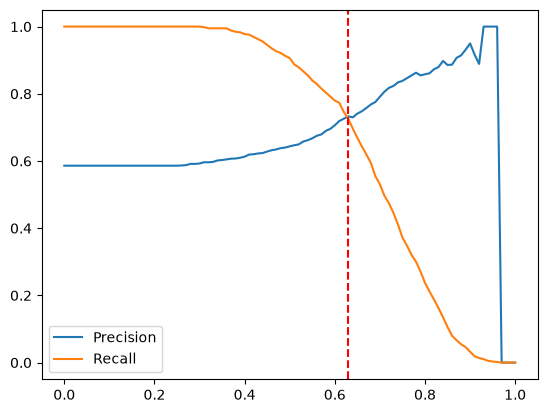

In [83]:
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0.0, 1.01, 0.01)

prec_scores = []
rec_scores = []
f1_scores = []

for threshold in thresholds:
    prec_score = precision_score(
        y_val, y_pred >= threshold, zero_division=0
    )
    rec_score = recall_score(
        y_val, y_pred >= threshold, zero_division=0
    )
    if prec_score+rec_score != 0:
        f1_score = 2*((prec_score*rec_score)/(prec_score+rec_score))
    else:
        f1 = 0

    prec_scores.append(prec_score)
    rec_scores.append(rec_score)
    f1_scores.append(f1_score)

prec_scores = np.array(prec_scores)
rec_scores = np.array(rec_scores)
f1_scores = np.array(f1_scores)
# Исключаем случаи, когда обе метрики равны нулю
mask = (prec_scores != 0) | (rec_scores != 0)

# Находим минимальную абсолютную разницу
diff = np.abs(prec_scores - rec_scores)
diff[~mask] = np.inf

idx = np.argmin(diff)


print(f'Threshold: {thresholds[idx]:.2f}')
print(f'Precision: {prec_scores[idx]:.3f}')
print(f'Recall: {rec_scores[idx]:.3f}')

idx_f1 = np.argmax(f1_scores)

print(f'Maximum F1-score: {f1_scores[idx_f1]:.3f}')
print(f'Best threshold: {thresholds[idx_f1]:.2f}')

plt.plot(thresholds, prec_scores, label='Precision')
plt.plot(thresholds, rec_scores, label='Recall')
plt.axvline(thresholds[idx], color='red', linestyle='--')
plt.legend()
plt.show()

In [84]:
from sklearn.model_selection import KFold

In [85]:
!pip install tqdm

In [102]:
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score

In [107]:
def train(X_train, y_train, C=1.0):
    dicts = X_train.to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)

    model = LogisticRegression(
        C=C,
        solver='liblinear',
        max_iter=1000
    )
    model.fit(X, y_train)

    return dv, model

In [108]:
def predict(X_val, dv, model):
    dicts = X_val.to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [111]:
from sklearn.metrics import roc_auc_score

n_splits = 5


kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]
    # Выделяем признаки
    X_train_fold = df_train.drop(columns=['converted'])
    X_val_fold = df_val.drop(columns=['converted'])

    # Выделяем целевую переменную
    y_train_fold = df_train.converted.values
    y_val_fold = df_val.converted.values
    dv, model = train(X_train_fold, y_train_fold, C=1.0)
    y_pred = predict(X_val_fold, dv, model)

    auc_val = roc_auc_score(y_val_fold, y_pred)
    scores.append(auc_val)

print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

C=1 0.732 +- 0.007


In [112]:
from sklearn.metrics import roc_auc_score

n_splits = 5

for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)
    
    scores = []
    
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
        # Выделяем признаки
        X_train_fold = df_train.drop(columns=['converted'])
        X_val_fold = df_val.drop(columns=['converted'])
    
        # Выделяем целевую переменную
        y_train_fold = df_train.converted.values
        y_val_fold = df_val.converted.values
        dv, model = train(X_train_fold, y_train_fold, C=C)
        y_pred = predict(X_val_fold, dv, model)
    
        auc_val = roc_auc_score(y_val_fold, y_pred)
        scores.append(auc_val)
    
    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
